<a href="https://colab.research.google.com/github/sagal1031rene-coder/3iatlas-galactic-backtracking/blob/main/apophis_close_encounter_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ==============================================================================
# PIPELINE AUTOMATIZADO: EFEMÉRIDES JPL HORIZONS E INTEGRACIÓN DE (99942) APOPHIS
# PROYECTO: MONITOREO INDEPENDIENTE DEL SOBREVUELO CERCANO DE ABRIL DE 2029
# AUTOR: RENÉ SAGAL ANDRADE (INVESTIGADOR INDEPENDIENTE / UCL ALUMNUS)
# ==============================================================================

# 1. INSTALACIÓN DE LAS LIBRERÍAS CIENTÍFICAS
!pip install -q astroquery rebound

import numpy as np
import pandas as pd
import rebound
from astroquery.jplhorizons import Horizons
import matplotlib.pyplot as plt

print("✓ Entorno Colab configurado. Astroquery y REBOUND instalados con éxito.\n")

# 2. CONSULTA AUTOMATIZADA AL SISTEMA HORIZONS DEL JPL
# ID de Apophis en el catálogo del JPL: 99942
# El sobrevuelo crítico es el 13 de abril de 2029. Inicializamos la consulta un poco antes.
target_id = '99942'
fecha_inicio = '2029-04-01'
fecha_fin = '2029-05-01'
pasos_tiempo = 500

print(f"Interrogando al servidor JPL Horizons para el asteroide {target_id}...")

# CORRECCIÓN DE REFERENCIA: Solicitamos los vectores de estado referenciados al Baricentro del Sistema Solar (@ssb)
obj_horizons = Horizons(id=target_id, location='@ssb',
                        epochs={'start': fecha_inicio, 'stop': fecha_fin, 'step': str(pasos_tiempo)})
vectors = obj_horizons.vectors()

# Convertimos los datos crudos a un DataFrame de Pandas para su manipulación
df_apophis = vectors.to_pandas()
print(f"✓ ¡Vectores cargados con éxito! Se extrajeron {len(df_apophis)} estados dinámicos.")

# Mostramos los elementos cartesianos iniciales extraídos (Posiciones en UA, Velocidades en UA/día)
df_apophis[['datetime_str', 'x', 'y', 'z', 'vx', 'vy', 'vz']].head()

✓ Entorno Colab configurado. Astroquery y REBOUND instalados con éxito.

Interrogando al servidor JPL Horizons para el asteroide 99942...
✓ ¡Vectores cargados con éxito! Se extrajeron 501 estados dinámicos.


,datetime_str,x,y,z,vx,vy,vz
0,A.D. 2029-Apr-01 00:00:00.0000,-1.011344,-0.222120,-0.012066,0.005595,-0.014758,0.000922
1,A.D. 2029-Apr-01 01:26:24.0000,-1.011008,-0.223006,-0.012011,0.005611,-0.014755,0.000922
2,A.D. 2029-Apr-01 02:52:48.0000,-1.010671,-0.223891,-0.011956,0.005627,-0.014751,0.000922
3,A.D. 2029-Apr-01 04:19:12.0000,-1.010333,-0.224776,-0.011900,0.005643,-0.014748,0.000922
4,A.D. 2029-Apr-01 05:45:36.0000,-1.009994,-0.225661,-0.011845,0.005660,-0.014744,0.000923


Inicializando simulación N-Cuerpos completa con los planetas del Sistema Solar...
Cargando efemérides de los cuerpos masivos desde el JPL...
Searching NASA Horizons for 'Sun'... 
Found: Sun (10) 
Searching NASA Horizons for '199'... 
Found: Mercury (199) 
Searching NASA Horizons for '299'... 
Found: Venus (299) 
Searching NASA Horizons for '399'... 
Found: Earth (399) 
Searching NASA Horizons for '301'... 
Found: Moon (301) 
Searching NASA Horizons for '499'... 
Found: Mars (499) 
Searching NASA Horizons for '599'... 
Found: Jupiter (599) 
Searching NASA Horizons for '699'... 
Found: Saturn (699) 
Searching NASA Horizons for '799'... 
Found: Uranus (799) 
Searching NASA Horizons for '899'... 
Found: Neptune (899) 
Ejecutando bucle de integración adaptativa IAS15 (Tierra: índice 3, Apophis: índice 10)...

             RESULTADOS DE LA SIMULACIÓN COMPLETA                 
✓ Distancia mínima de aproximación calculada: 38,159.53 km
✓ Días transcurridos desde el 1 de abril de 2029: 12.9129 

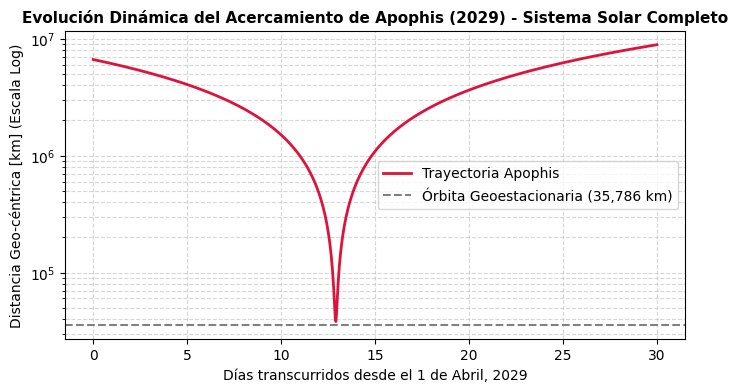

In [ ]:
# ==============================================================================
# ENTORNO N-CUERPOS COMPLETO: ACOPLAMIENTO DE EFEMÉRIDES E INTEGRACIÓN ADAPTATIVA
# LIBRERÍA: REBOUND (INTEGRADOR IAS15)
# PROYECTO: SIMULACIÓN DEL ENCUENTRO CERCANO TIERRA-APOPHIS (ABRIL 2029)
# AUTOR: RENÉ SAGAL ANDRADE (INVESTIGADOR INDEPENDIENTE / UCL ALUMNUS)
# ==============================================================================

print("Inicializando simulación N-Cuerpos completa con los planetas del Sistema Solar...")

# 1. CONFIGURACIÓN DEL ENTORNO REBOUND EN UNIDADES ASTRONÓMICAS
sim = rebound.Simulation()
sim.integrator = "ias15"  # Integrador Gauss-Radau de 15.º orden
sim.units = ('AU', 'd', 'Msun')  # Unidades: UA, Días, Masas Solares

# 2. INYECCIÓN DE LOS CUERPOS DEL SISTEMA SOLAR DESDE HORIZONS A LA FECHA DE INICIO (2029-04-01)
# Cargamos efemérides de alta precisión de todos los planetas principales del JPL
print("Cargando efemérides de los cuerpos masivos desde el JPL...")
sim.add("Sun", date="2029-04-01 00:00")     # Índice 0
sim.add("199", date="2029-04-01 00:00")   # Mercurio - Índice 1
sim.add("299", date="2029-04-01 00:00")   # Venus - Índice 2
sim.add("399", date="2029-04-01 00:00")   # Tierra - Índice 3
sim.add("301", date="2029-04-01 00:00")   # Luna - Índice 4
sim.add("499", date="2029-04-01 00:00")   # Marte - Índice 5
sim.add("599", date="2029-04-01 00:00")   # Júpiter - Índice 6
sim.add("699", date="2029-04-01 00:00")   # Saturno - Índice 7
sim.add("799", date="2029-04-01 00:00")   # Urano - Índice 8
sim.add("899", date="2029-04-01 00:00")   # Neptuno - Índice 9

# 3. EXTRACCIÓN E INYECCIÓN DEL VECTOR DE ESTADO INICIAL DE APOPHIS (Fila 0 de tu consulta)
estado_inicial = df_apophis.iloc[0]
sim.add(
    x=estado_inicial['x'], y=estado_inicial['y'], z=estado_inicial['z'],
    vx=estado_inicial['vx'], vy=estado_inicial['vy'], vz=estado_inicial['vz']
)                                          # Apophis - Índice 10

sim.move_to_com()  # Mover al centro de masa del sistema unificado completo

# 4. BUCLE DE INTEGRACIÓN FINA PARA DETECTAR EL MÁXIMO ACERCAMIENTO
# Simulación por 30 días (del 1 de abril al 1 de mayo de 2029)
N_pasos = 1000
tiempos = np.linspace(0, 30.0, N_pasos)

distancias_tierra_km = []
fechas_simulacion = []

# Constante de conversión: 1 UA = 149,597,870.7 km
UA_A_KM = 149597870.7

# Índices estáticos bien definidos en base a la inserción secuencial
idx_tierra = 3
idx_apophis = 10

print(f"Ejecutando bucle de integración adaptativa IAS15 (Tierra: índice {idx_tierra}, Apophis: índice {idx_apophis})...")
for t in tiempos:
    sim.integrate(t)

    # Extraer posiciones instantáneas de la Tierra y Apophis
    pos_tierra = np.array([sim.particles[idx_tierra].x, sim.particles[idx_tierra].y, sim.particles[idx_tierra].z])
    pos_apophis = np.array([sim.particles[idx_apophis].x, sim.particles[idx_apophis].y, sim.particles[idx_apophis].z])

    # Cálculo de la distancia euclidiana tridimensional
    r_relativa_ua = np.linalg.norm(pos_apophis - pos_tierra)
    distancias_tierra_km.append(r_relativa_ua * UA_A_KM)

# 5. ANÁLISIS DE RESULTADOS DINÁMICOS EN PANTALLA
dist_minima = min(distancias_tierra_km)
idx_minimo = np.argmin(distancias_tierra_km)
tiempo_perigeo = tiempos[idx_minimo]

print("\n==================================================================")
print("             RESULTADOS DE LA SIMULACIÓN COMPLETA                 ")
print("==================================================================")
print(f"✓ Distancia mínima de aproximación calculada: {dist_minima:,.2f} km")
print(f"✓ Días transcurridos desde el 1 de abril de 2029: {tiempo_perigeo:.4f} días")
print(f"  (Altitud aproximada sobre la superficie terrestre: {dist_minima - 6371:,.2f} km)")
print("==================================================================")

# 6. GRÁFICA DE DIAGNÓSTICO EVOLUTIVO DE DISTANCIA
plt.figure(figsize=(8, 4))
plt.plot(tiempos, distancias_tierra_km, color='crimson', lw=2, label='Trayectoria Apophis')
plt.axhline(35786, color='gray', linestyle='--', label='Órbita Geoestacionaria (35,786 km)')
plt.yscale('log')
plt.xlabel('Días transcurridos desde el 1 de Abril, 2029')
plt.ylabel('Distancia Geo-céntrica [km] (Escala Log)')
plt.title('Evolución Dinámica del Acercamiento de Apophis (2029) - Sistema Solar Completo', fontsize=11, fontweight='bold')
plt.legend(frameon=True)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

### Guardar y Exportar Resultados de la Simulación
Ejecuta la siguiente celda para almacenar localmente en tu entorno de Colab la gráfica en alta definición y un archivo CSV con la serie temporal de las distancias calculadas.

In [ ]:
# ==============================================================================
# EXPORTACIÓN DE DATOS Y GRÁFICOS
# ==============================================================================
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# 1. Guardar la Gráfica en Alta Resolución
plt.figure(figsize=(10, 5), dpi=300) # Definimos alta resolución (300 DPI)
plt.plot(tiempos, distancias_tierra_km, color='crimson', lw=2, label='Trayectoria Apophis')
plt.axhline(35786, color='gray', linestyle='--', label='Órbita Geoestacionaria (35,786 km)')
plt.yscale('log')
plt.xlabel('Días transcurridos desde el 1 de Abril, 2029')
plt.ylabel('Distancia Geo-céntrica [km] (Escala Log)')
plt.title('Evolución Dinámica del Acercamiento de Apophis (2029)', fontsize=12, fontweight='bold')
plt.legend(frameon=True)
plt.grid(True, which="both", ls="--", alpha=0.5)

# Guardamos la imagen en el almacenamiento local de Colab
nombre_grafica = "apophis_sobrevuelo_2029.png"
plt.savefig(nombre_grafica, bbox_inches='tight', dpi=300)
plt.close()
print(f"✓ Gráfica guardada como: '{nombre_grafica}'")

# 2. Guardar la Serie Temporal de Datos en un CSV
df_resultados = pd.DataFrame({
    'Dias_Desde_Abri_1': tiempos,
    'Distancia_Tierra_km': distancias_tierra_km
})

nombre_csv = "apophis_distancias_2029.csv"
df_resultados.to_csv(nombre_csv, index=False)
print(f"✓ Datos de trayectoria exportados como: '{nombre_csv}'")

# 3. Descarga Automática al Ordenador del Usuario (Opcional)
# Descomenta las siguientes líneas si deseas que el navegador los descargue directamente:
# files.download(nombre_grafica)
# files.download(nombre_csv)

✓ Gráfica guardada como: 'apophis_sobrevuelo_2029.png'
✓ Datos de trayectoria exportados como: 'apophis_distancias_2029.csv'


In [ ]:
#Se corrige celda 2
sim.add("Sun")
sim.add("Earth")
sim.add("Moon")
# Forzamos la descarga del vector de estado real del JPL para la fecha de inicio
sim.add("Sun", date="2029-04-01 00:00")
sim.add("399", date="2029-04-01 00:00")   # 399 es el código JPL para el centro de la Tierra
sim.add("301", date="2029-04-01 00:00")   # 301 es el código JPL para la Luna
